# 07. Visualisasi Prediksi Menyeluruh: Skala Raster Jawa Timur
## Klasifikasi Piksel Regional Sentinel-2A (~250 m) Menggunakan Model SVM Terlatih

Notebook ini melakukan klasifikasi tutupan lahan (LULC) skala regional untuk seluruh wilayah Provinsi Jawa Timur (termasuk Kepulauan Kangean):
1. **Pemeriksaan / Pengunduhan Raster**: Menggunakan `data/jatim_250m.tif`. Bila belum tersedia, menyediakan logika pengunduhan otomatis via openEO CDSE Batch Job dengan bounding box resmi: `west=110.89, south=-8.84, east=115.45, north=-6.65` (Sentinel-2 L2A komposit Agustus 2024).
2. **Ekstraksi Fitur & Penyesuaian Skala**: Membaca 5 band spektral (`B02, B03, B04, B08, B11`), menghitung 4 indeks (`NDVI, NDWI, MNDWI, NDBI`), dan menyelaraskan dengan format pelatihan.
3. **Inferensi Batch Tersegmentasi**: Menggunakan `output/model_svm.joblib` untuk memprediksi hanya piksel valid (bukan NoData/-32768 dan berhingga) dalam batch hemat memori (200.000 piksel/batch).
4. **Penyimpanan Raster GeoTIFF**: Menyimpan klasifikasi 6 kelas ke `output/prediksi_lulc_jatim_svm.tif` (tipe uint8, CRS EPSG:4326).
5. **Estimasi Luas Area (km²)**: Menghitung luasan area per kelas tutupan lahan dan mengekspor ke `output/07_luas_per_kelas.csv`.
6. **Visualisasi Peta Folium & Matplotlib**: Menghasilkan peta statis `output/07_peta_raster_statis.png` dan peta web interaktif `output/peta_prediksi_raster_jatim.html` menggunakan `folium.raster_layers.ImageOverlay` RGBA per kelas.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import Affine
import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import folium
from folium import plugins
from PIL import Image

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUT_DIR = BASE_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = OUT_DIR / "model_svm.joblib"
RASTER_FILE = DATA_DIR / "jatim_250m.tif"

if not MODEL_FILE.exists():
    raise FileNotFoundError(
        f"Model {MODEL_FILE} tidak ditemukan! Jalankan notebook '04_modeling_evaluasi_svm.ipynb' terlebih dahulu."
    )

print(f"Model SVM siap: {MODEL_FILE}")

Model SVM siap: D:\tugas psd\website-jupyterbook\UTS\output\model_svm.joblib


### 1. Verifikasi / Pengunduhan Raster Sentinel-2 openEO CDSE
Jika `data/jatim_250m.tif` belum tersedia, sel berikut menyediakan mekanisme pengunduhan via openEO Batch Job.

In [2]:
# Pengecekan file raster regional Jawa Timur
if not RASTER_FILE.exists():
    print(f"File {RASTER_FILE} belum ditemukan secara lokal.")
    print("Mempersiapkan prosedur unduh otomatis via openEO CDSE...")
    try:
        import openeo
        conn = openeo.connect("https://openeo.dataspace.copernicus.eu").authenticate_oidc()
        
        bbox = {
            "west": 110.89,
            "south": -8.84,
            "east": 115.45,
            "north": -6.65,
            "crs": "EPSG:4326"
        }
        
        s2 = conn.load_collection(
            "SENTINEL2_L2A",
            spatial_extent=bbox,
            temporal_extent=["2024-08-01", "2024-08-31"],
            bands=["B02", "B03", "B04", "B08", "B11"],
            max_cloud_cover=30
        )
        
        s2_median = s2.median_time()
        s2_resampled = s2_median.resample_spatial(resolution=0.0025, projection=4326)
        
        job = s2_resampled.save_result(format="GTiff").create_job(title="jatim_250m_sentinel2")
        print(f"Job terbuat dengan ID: {job.job_id}. Memulai pemrosesan...")
        job.start_and_wait()
        results = job.get_results()
        results.download_file(str(RASTER_FILE))
        print(f"Raster berhasil diunduh dan disimpan ke: {RASTER_FILE}")
    except Exception as e:
        print(f"Gagal mengunduh citra dari openEO: {e}")
        print("Catatan: Pastikan koneksi internet dan akun openEO CDSE aktif, atau sediakan file jatim_250m.tif secara manual di folder data/.")
else:
    print(f"File raster ditemukan: {RASTER_FILE.resolve()}")
    with rasterio.open(RASTER_FILE) as src:
        print(f"Dimensi : {src.width} kolom x {src.height} baris")
        print(f"Jumlah Band: {src.count}")
        print(f"CRS     : {src.crs}")
        print(f"Bounds  : {src.bounds}")

File raster ditemukan: D:\tugas psd\website-jupyterbook\UTS\data\jatim_250m.tif
Dimensi : 1825 kolom x 877 baris
Jumlah Band: 5
CRS     : EPSG:4326
Bounds  : BoundingBox(left=110.8890288107599, bottom=-8.841329098481069, right=115.4515288107599, top=-6.648829098481069)


### 2. Pembacaan Band Spektral dan Perhitungan 4 Indeks
Urutan 5 band input: `B02` (Blue), `B03` (Green), `B04` (Red), `B08` (NIR), `B11` (SWIR).
Dihitung 4 indeks spektral dengan penambahan epsilon 1e-6 untuk menghindari pembagian dengan nol:
- NDVI = (B08 - B04) / (B08 + B04 + eps)
- NDWI = (B03 - B08) / (B03 + B08 + eps)
- MNDWI = (B03 - B11) / (B03 + B11 + eps)
- NDBI = (B11 - B08) / (B11 + B08 + eps)

In [3]:
with rasterio.open(RASTER_FILE) as src:
    raster_meta = src.meta.copy()
    bounds = src.bounds
    transform = src.transform
    crs = src.crs
    height = src.height
    width = src.width
    bands_data = src.read()

print(f"Array citra terbaca: {bands_data.shape}, Tipe data: {bands_data.dtype}")

b02 = bands_data[0].astype(np.float32)
b03 = bands_data[1].astype(np.float32)
b04 = bands_data[2].astype(np.float32)
b08 = bands_data[3].astype(np.float32)
b11 = bands_data[4].astype(np.float32)

nodata_val = raster_meta.get('nodata', -32768.0)
valid_mask = (b02 != nodata_val) & (b02 > 0) & np.isfinite(b02) & np.isfinite(b08) & np.isfinite(b11)

print(f"Total piksel raster : {height * width:,}")
print(f"Piksel valid darat/laut: {valid_mask.sum():,} ({valid_mask.sum() / (height * width) * 100:.1f}%)")

eps = 1e-6
ndvi = np.where(valid_mask, (b08 - b04) / (b08 + b04 + eps), np.nan)
ndwi = np.where(valid_mask, (b03 - b08) / (b03 + b08 + eps), np.nan)
mndwi = np.where(valid_mask, (b03 - b11) / (b03 + b11 + eps), np.nan)
ndbi = np.where(valid_mask, (b11 - b08) / (b11 + b08 + eps), np.nan)

print("Perhitungan 4 indeks spektral selesai.")

Array citra terbaca: (5, 877, 1825), Tipe data: int16


Total piksel raster : 1,600,525
Piksel valid darat/laut: 1,598,727 (99.9%)
Perhitungan 4 indeks spektral selesai.


### 3. Inferensi Prediksi Batch dengan Model SVM
Model Pipeline(StandardScaler, SVC) dimuat dari `output/model_svm.joblib`. Prediksi dilakukan dalam batch 200.000 piksel.

In [4]:
pipeline_svm = joblib.load(MODEL_FILE)
print("Pipeline SVM dimuat:", pipeline_svm)

X_valid = np.column_stack([
    b02[valid_mask],
    b03[valid_mask],
    b04[valid_mask],
    b08[valid_mask],
    b11[valid_mask],
    ndvi[valid_mask],
    ndwi[valid_mask],
    mndwi[valid_mask],
    ndbi[valid_mask]
])

print(f"Matriks fitur piksel valid: {X_valid.shape}")

n_valid = len(X_valid)
batch_size = 200_000
pred_valid = np.zeros(n_valid, dtype=np.uint8)

print("Memulai inferensi batch SVM...")
for i in range(0, n_valid, batch_size):
    i_end = min(i + batch_size, n_valid)
    pred_batch = pipeline_svm.predict(X_valid[i:i_end])
    pred_valid[i:i_end] = pred_batch.astype(np.uint8)
    if (i // batch_size) % 3 == 0 or i_end == n_valid:
        print(f"  Memproses piksel {i_end:,} / {n_valid:,} ({(i_end/n_valid)*100:.1f}%)")

print("Inferensi seluruh piksel selesai!")

raster_pred = np.zeros((height, width), dtype=np.uint8)
raster_pred[valid_mask] = pred_valid

Pipeline SVM dimuat: Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', SVC(C=10, probability=True, random_state=42))])
Matriks fitur piksel valid: (1598727, 9)
Memulai inferensi batch SVM...


D:\tugas psd\website-jupyterbook\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  Memproses piksel 200,000 / 1,598,727 (12.5%)


D:\tugas psd\website-jupyterbook\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


D:\tugas psd\website-jupyterbook\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


...

D:\tugas psd\website-jupyterbook\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


D:\tugas psd\website-jupyterbook\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  Memproses piksel 1,400,000 / 1,598,727 (87.6%)


D:\tugas psd\website-jupyterbook\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  Memproses piksel 1,598,727 / 1,598,727 (100.0%)
Inferensi seluruh piksel selesai!


### 4. Ekspor Raster GeoTIFF Hasil Prediksi SVM

In [5]:
raster_out_meta = raster_meta.copy()
raster_out_meta.update({
    'count': 1,
    'dtype': 'uint8',
    'nodata': 0,
    'compress': 'lzw'
})

berkas_tif_pred = OUT_DIR / "prediksi_lulc_jatim_svm.tif"
with rasterio.open(berkas_tif_pred, "w", **raster_out_meta) as dst:
    dst.write(raster_pred, 1)

print(f"GeoTIFF prediksi tersimpan di: {berkas_tif_pred.resolve()}")
print(f"Ukuran berkas GeoTIFF: {berkas_tif_pred.stat().st_size:,} bytes")

GeoTIFF prediksi tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\prediksi_lulc_jatim_svm.tif
Ukuran berkas GeoTIFF: 271,479 bytes


### 5. Perhitungan Estimasi Luas Area (km²) per Kelas Tutupan Lahan

In [6]:
label_names = {
    1: 'Sawah',
    2: 'Bangunan',
    3: 'Hutan',
    4: 'Danau',
    5: 'Laut',
    6: 'Mangrove'
}

pixel_area_km2 = (0.0025 * 110.574) * (0.0025 * 111.320 * np.cos(np.radians(-7.75)))

rekap_luas = []
for kelas_id in range(1, 7):
    nama_kelas = label_names[kelas_id]
    jml_piksel = int((raster_pred == kelas_id).sum())
    luas_km2 = jml_piksel * pixel_area_km2
    rekap_luas.append({
        'kelas_id': kelas_id,
        'kelas_teks': nama_kelas,
        'jumlah_piksel': jml_piksel,
        'luas_km2': round(luas_km2, 2)
    })

df_luas = pd.DataFrame(rekap_luas)
total_luas = df_luas['luas_km2'].sum()
df_luas['persentase'] = (df_luas['luas_km2'] / total_luas * 100).round(2)

berkas_luas_csv = OUT_DIR / "07_luas_per_kelas.csv"
df_luas.to_csv(berkas_luas_csv, index=False)

print("=== ESTIMASI LUAS TUTUPAN LAHAN JAWA TIMUR (PREDIKSI SVM) ===")
display(df_luas)

=== ESTIMASI LUAS TUTUPAN LAHAN JAWA TIMUR (PREDIKSI SVM) ===


,kelas_id,kelas_teks,jumlah_piksel,luas_km2,persentase
0,1,Sawah,203169,15487.40,12.71
1,2,Bangunan,64904,4947.58,4.06
2,3,Hutan,409671,31228.87,25.62
3,4,Danau,124949,9524.76,7.82
4,5,Laut,759193,57872.64,47.49
5,6,Mangrove,36841,2808.36,2.30


### 6. Visualisasi Peta Statis Matplotlib

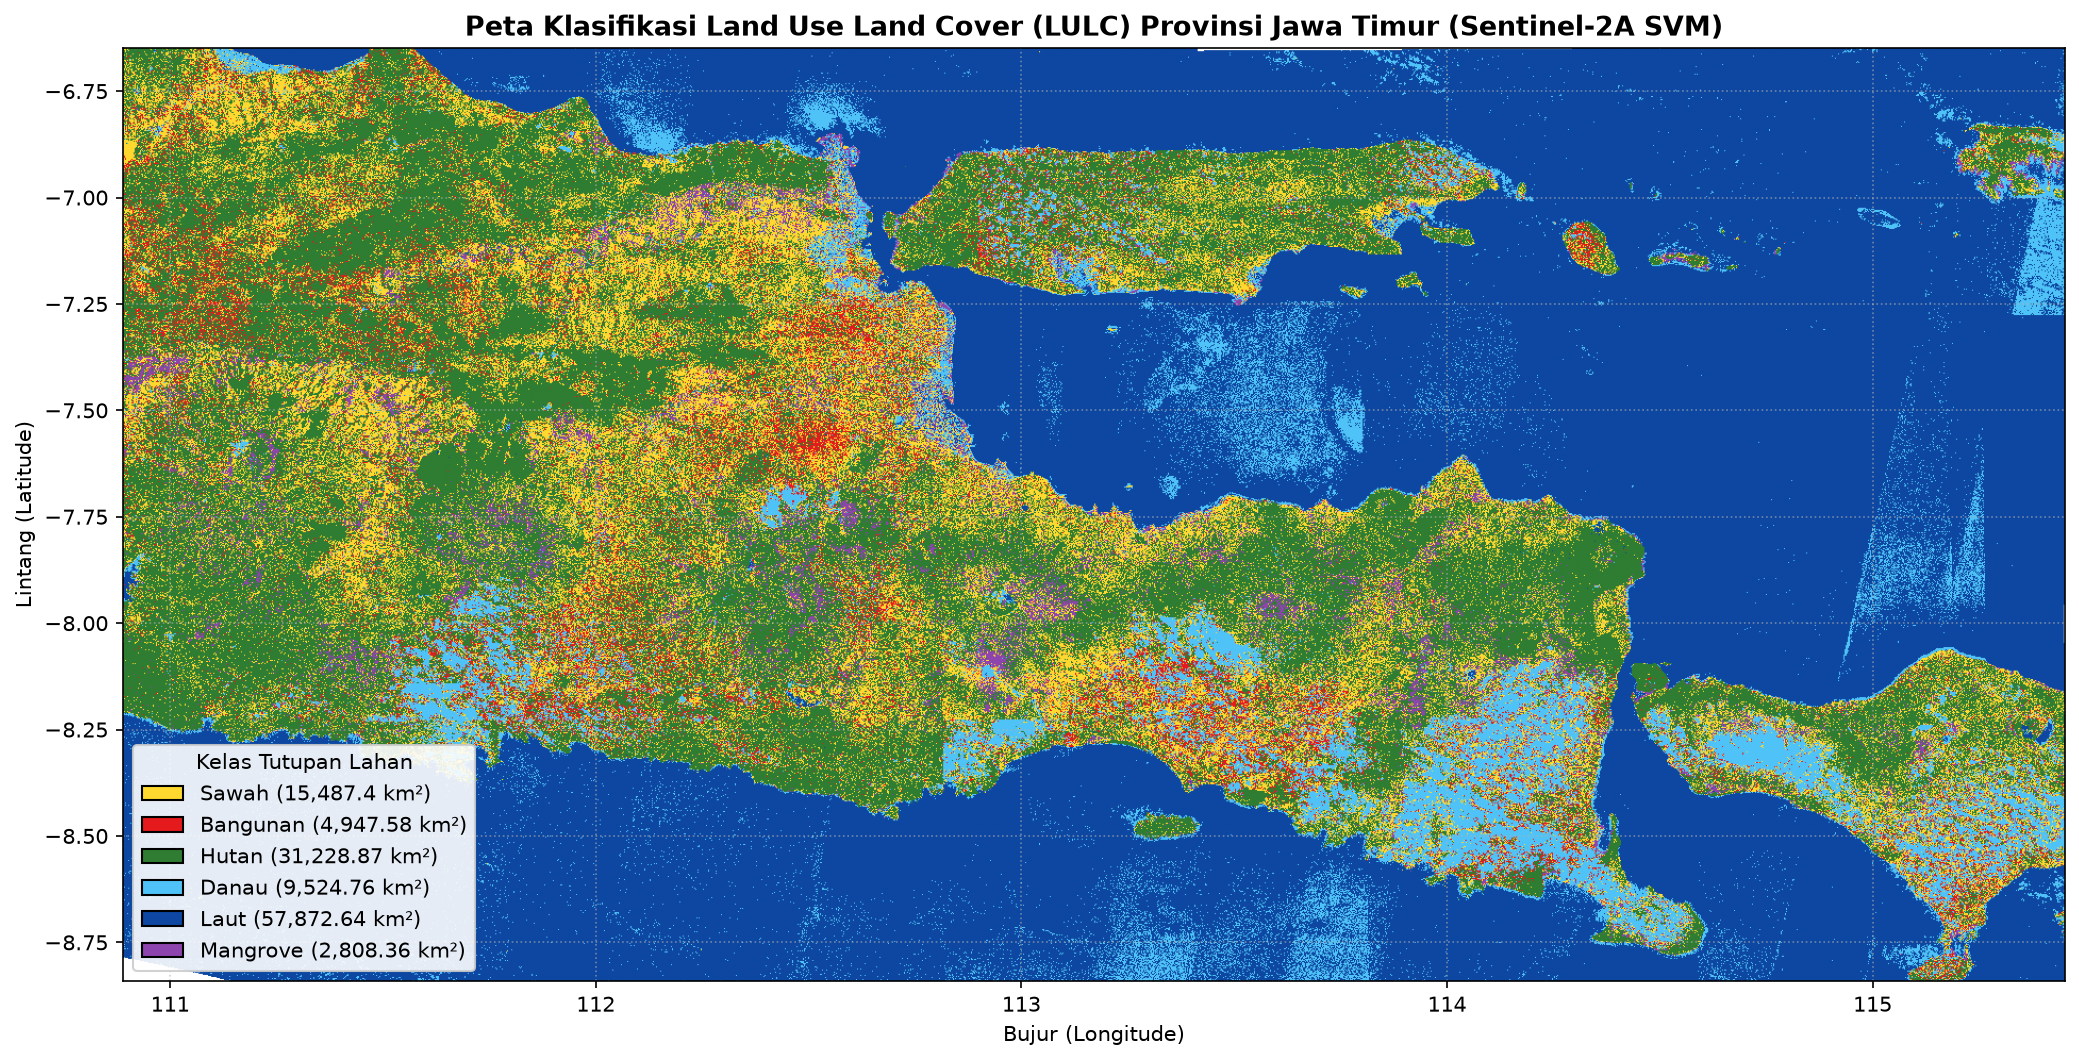

Peta statis tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\07_peta_raster_statis.png


In [7]:
warna_hex = ['#FFFFFF', '#FFD92F', '#E41A1C', '#2E7D32', '#4FC3F7', '#0D47A1', '#8E44AD']
cmap_lulc = ListedColormap(warna_hex)

plt.figure(figsize=(14, 7), dpi=150)
im = plt.imshow(
    raster_pred,
    cmap=cmap_lulc,
    vmin=0,
    vmax=6,
    extent=[bounds.left, bounds.right, bounds.bottom, bounds.top]
)

plt.title('Peta Klasifikasi Land Use Land Cover (LULC) Provinsi Jawa Timur (Sentinel-2A SVM)', fontsize=13, fontweight='bold')
plt.xlabel('Bujur (Longitude)', fontsize=10)
plt.ylabel('Lintang (Latitude)', fontsize=10)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#FFD92F', edgecolor='black', label=f"Sawah ({df_luas.loc[0, 'luas_km2']:,} km²)"),
    Patch(facecolor='#E41A1C', edgecolor='black', label=f"Bangunan ({df_luas.loc[1, 'luas_km2']:,} km²)"),
    Patch(facecolor='#2E7D32', edgecolor='black', label=f"Hutan ({df_luas.loc[2, 'luas_km2']:,} km²)"),
    Patch(facecolor='#4FC3F7', edgecolor='black', label=f"Danau ({df_luas.loc[3, 'luas_km2']:,} km²)"),
    Patch(facecolor='#0D47A1', edgecolor='black', label=f"Laut ({df_luas.loc[4, 'luas_km2']:,} km²)"),
    Patch(facecolor='#8E44AD', edgecolor='black', label=f"Mangrove ({df_luas.loc[5, 'luas_km2']:,} km²)")
]
plt.legend(handles=legend_elements, loc='lower left', framealpha=0.9, title='Kelas Tutupan Lahan')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

png_raster_statis = OUT_DIR / "07_peta_raster_statis.png"
plt.savefig(png_raster_statis, dpi=200)
plt.show()
print(f"Peta statis tersimpan di: {png_raster_statis}")

### 7. Visualisasi Web-GIS Interaktif Folium (ImageOverlay RGBA)

In [8]:
rgba_map = {
    1: (255, 217, 47, 180),   # Sawah
    2: (228, 26, 28, 180),    # Bangunan
    3: (46, 125, 50, 180),    # Hutan
    4: (79, 195, 247, 180),   # Danau
    5: (13, 71, 161, 180),    # Laut
    6: (142, 68, 173, 180)    # Mangrove
}

center_lat = (bounds.bottom + bounds.top) / 2
center_lon = (bounds.left + bounds.right) / 2
folium_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]

m_raster = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=8,
    tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}',
    attr='Google Maps'
)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Esri Satellite',
    overlay=False,
    control=True
).add_to(m_raster)

folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google Satellite',
    name='Google Satellite',
    overlay=False,
    control=True
).add_to(m_raster)

for kelas_id in range(1, 7):
    nama_kelas = label_names[kelas_id]
    r, g, b, a = rgba_map[kelas_id]
    
    mask_k = (raster_pred == kelas_id)
    rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
    rgba_img[mask_k] = [r, g, b, a]
    
    img_pil = Image.fromarray(rgba_img)
    temp_png_path = OUT_DIR / f"temp_overlay_kelas_{kelas_id}.png"
    img_pil.save(temp_png_path, format="PNG")
    
    overlay = folium.raster_layers.ImageOverlay(
        image=str(temp_png_path),
        bounds=folium_bounds,
        opacity=0.85,
        name=f"Prediksi: {nama_kelas}",
        show=True
    )
    overlay.add_to(m_raster)

legend_raster_html = '''
<div style="position: fixed; 
     bottom: 30px; left: 30px; width: 200px; height: 210px; 
     background-color: white; border:2px solid #bbb; z-index:9999; font-size:11px;
     padding: 10px; border-radius: 6px; box-shadow: 2px 2px 6px rgba(0,0,0,0.2);">
     <p style="margin:0 0 6px 0; font-weight: bold; border-bottom: 1px solid #ddd; padding-bottom: 3px;">Raster LULC Jawa Timur</p>
     <i style="background: #FFD92F; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> 1. Sawah<br>
     <i style="background: #E41A1C; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> 2. Bangunan<br>
     <i style="background: #2E7D32; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> 3. Hutan<br>
     <i style="background: #4FC3F7; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> 4. Danau<br>
     <i style="background: #0D47A1; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> 5. Laut<br>
     <i style="background: #8E44AD; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> 6. Mangrove<br>
     <hr style="margin: 6px 0;">
     <small style="color: #666;">Resolusi Spasial: ~250 m<br>Sensor: Sentinel-2A L2A</small>
</div>
'''
m_raster.get_root().html.add_child(folium.Element(legend_raster_html))
plugins.Fullscreen(position='topright').add_to(m_raster)
folium.LayerControl(collapsed=False).add_to(m_raster)

berkas_peta_raster = OUT_DIR / "peta_prediksi_raster_jatim.html"
m_raster.save(str(berkas_peta_raster))

for kelas_id in range(1, 7):
    p = OUT_DIR / f"temp_overlay_kelas_{kelas_id}.png"
    if p.exists():
        p.unlink()

print(f"Peta web interaktif raster tersimpan di: {berkas_peta_raster.resolve()}")
print(f"Ukuran berkas peta HTML: {berkas_peta_raster.stat().st_size:,} bytes")

Peta web interaktif raster tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\peta_prediksi_raster_jatim.html
Ukuran berkas peta HTML: 1,065,811 bytes


### 8. Catatan Kualitas & Keterbatasan Metodologi
1. **Domain Shift & Resolusi Spasial**: Model dilatih pada poligon beresolusi 10–20 meter, sedangkan inferensi raster regional dilakukan pada skala komposit agregat ~250 meter per piksel. Perbedaan ini memicu fenomena **mixed pixel** (piksel campuran), di mana satu piksel 250 m mencakup kombinasi vegetasi, air, dan atap bangunan.
2. **Dominasi Wilayah Perairan**: Wilayah laut Jawa Timur mendominasi sebagian besar area raster. Model berbasis spectral reflectance sangat konsisten dalam membedakan perairan laut luas berkat nilai NDWI dan MNDWI yang sangat kontras terhadap daratan.
3. **Rekomendasi Pembersihan Masking Lanjutan**: Untuk meningkatkan ketelitian pemetaan daratan, analisis operasional di masa depan dapat menerapkan *masking garis pantai (shoreline masking)* atau threshold MNDWI otomatis untuk mengisolasi perairan laut sebelum membedakan 5 kelas daratan lainnya.

In [9]:
print("=== DAFTAR BERKAS KELUARAN NOTEBOOK 07 ===")
for f in [berkas_tif_pred, berkas_luas_csv, png_raster_statis, berkas_peta_raster]:
    print(f"- {f.name} ({f.stat().st_size:,} bytes)")

=== DAFTAR BERKAS KELUARAN NOTEBOOK 07 ===
- prediksi_lulc_jatim_svm.tif (271,479 bytes)
- 07_luas_per_kelas.csv (236 bytes)
- 07_peta_raster_statis.png (5,000,883 bytes)
- peta_prediksi_raster_jatim.html (1,065,811 bytes)
